# RGB-D シーンフロー補正（第0.3版）の再現チェック

配布アーカイブを展開し、**保存済みの推定出力から凍結メトリクスを再計算して突合**します。

## 何を確かめるか

配布物は 3 種類あります。結果（`data/`）、理論（`docs/`）、そして実装
（`scene_flow_primitives/`）。実装が届いたことで、再現は二段階になりました。

1. **実行再現**: 配布実装をビルドし、自動試験 94 件と、保存済み推定 1 件の再計算
   （配列が完全一致すること）を確認する → `just build` / `just upstream-test` / `just verify-upstream`
2. **評価量の再現**: 保存配列だけから凍結メトリクスを**独立に**再計算し、全 70 組で突合する
   → 本 Notebook と `just reproduce`

正本の理論書は `docs/theory_ja.tex`（PDF は `docs/theory_ja.pdf`）です。


In [1]:
import sys
from pathlib import Path

import numpy as np

LAB = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(LAB / "src") not in sys.path:
    sys.path.insert(0, str(LAB / "src"))

%matplotlib inline
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 84

from IPython.display import Markdown, display  # noqa: E402
from rgbd_sceneflow import archive, figures, metrics, tables  # noqa: E402

print("lab:", LAB)
print("data root:", archive.DATA_ROOT, "exists:", archive.DATA_ROOT.is_dir())


lab: /home/inaho-omen/Project/rgbd_sceneflow_sandbox
data root: /home/inaho-omen/Project/rgbd_sceneflow_sandbox/data exists: True


## 1. アーカイブの索引

`data/` 以下に、split ごとのケースと手法ごとの保存結果が入っています。


In [2]:
from rgbd_sceneflow.archive import case_count, iter_cases, result_count, SPLITS

counts = case_count()
lines = ["| split | ケース数 |", "|---|---:|"]
for split in SPLITS:
    lines.append(f"| `{split}` | {counts.get(split, 0)} |")
display(Markdown("\n".join(lines)))
print("ケース総数:", sum(counts.values()), "／手法つき保存結果（json）:", result_count())

sample = next(iter_cases())
print("例:", sample.key)
print("  手法:", ", ".join(sample.methods()))
print("  入力:", ", ".join(sorted(sample.inputs())))


| split | ケース数 |
|---|---:|
| `ablation` | 1 |
| `heldout` | 6 |
| `retest` | 6 |
| `stress` | 8 |

ケース総数: 21 ／手法つき保存結果（json）: 70
例: ablation/gallery_seed37
  手法: affine_photo, balanced4, cold_start, exact_kernel_only, full_search, long_solver, no_bound, no_edges, no_identity, no_reciprocal, no_rigid, no_rigid_quadratic, quadratic_geometry, quick, standard, tv, unfused, v02, weak_rigid
  入力: coherent_outlier, depth0, depth1, flow_dis, flow_dis_backward, flow_observed, gray0, gray1, gt_depth0, gt_depth1, gt_flow, gt_inside, gt_labels0, gt_labels1, gt_moving, gt_normal0, gt_normal1, gt_occluded, gt_outside, gt_scene_flow, gt_visible, injected_outlier, intrinsics, rgb0, rgb1


## 2. 記録された環境（当時の実行環境）


In [3]:
env = archive.environment()
deps = archive.dependency_versions()

rows = ["| 項目 | 値 |", "|---|---|"]
rows.append(f"| Python | `{deps['python']}` |")
for name, version in deps["packages"].items():
    rows.append(f"| {name} | `{version}` |")
rows.append(f"| numpy（実行時記録） | `{env['numpy']}` |")
rows.append(f"| スレッド | C++ 推定は単一。Python 側は `inference_threads={env['inference_threads']}` |")
rows.append("| GPU | 不使用（理論書 §6.3） |")
display(Markdown("\n".join(rows)))


| 項目 | 値 |
|---|---|
| Python | `3.13.5 (main, Jun 25 2025, 18:55:22) [GCC 14.2.0]` |
| numpy | `2.3.5` |
| scipy | `1.17.0` |
| matplotlib | `3.10.8` |
| pillow | `12.3.0` |
| opencv-python-headless | `4.13.0.92` |
| opencv-python | `4.13.0.92` |
| pytest | `9.0.2` |
| setuptools | `82.0.1` |
| wheel | `0.46.1` |
| uv | `0.10.0` |
| numpy（実行時記録） | `2.3.5` |
| スレッド | C++ 推定は単一。Python 側は `inference_threads=1` |
| GPU | 不使用（理論書 §6.3） |

## 3. 入力と正解（保存配列そのもの）


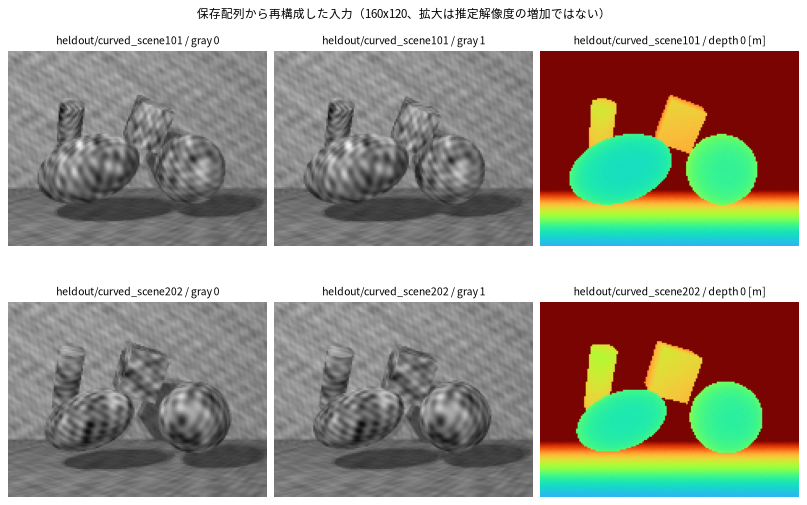

In [4]:
heldout = [c for c in iter_cases() if c.split == "heldout"]
figures.show(figures.figure_inputs(heldout[:2]))


正解（真値）も同じ保存配列に入っています。推定結果と混ぜずに、正解だけを並べます。
光流は Middlebury の色相環（向き＝色、大きさ＝明度）、3 次元変位は XYZ→RGB
（赤=x、緑=y、青=z。0 は中間色）で表示します。


heldout/curved_scene101


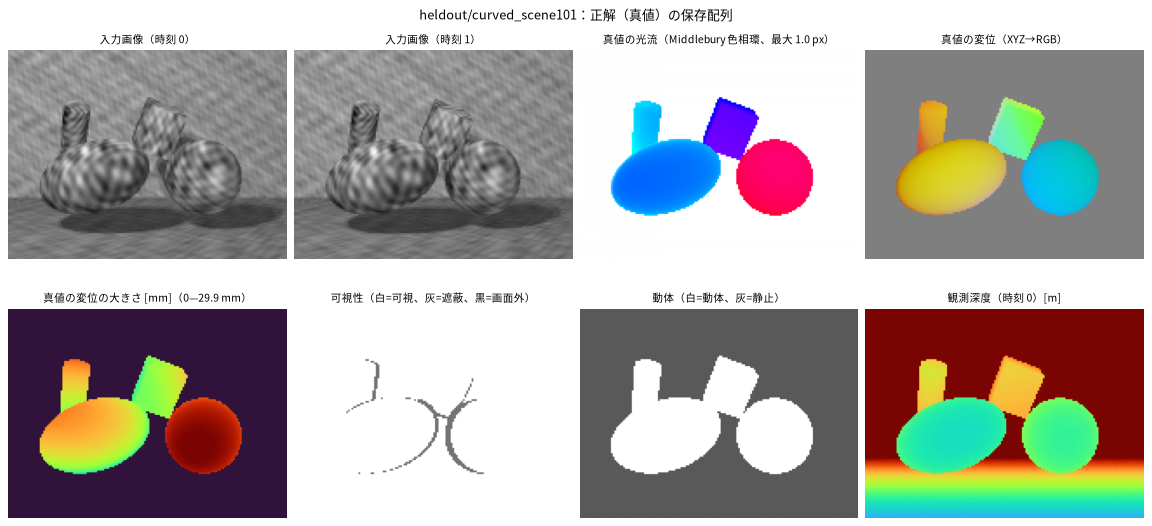

heldout/curved_scene202


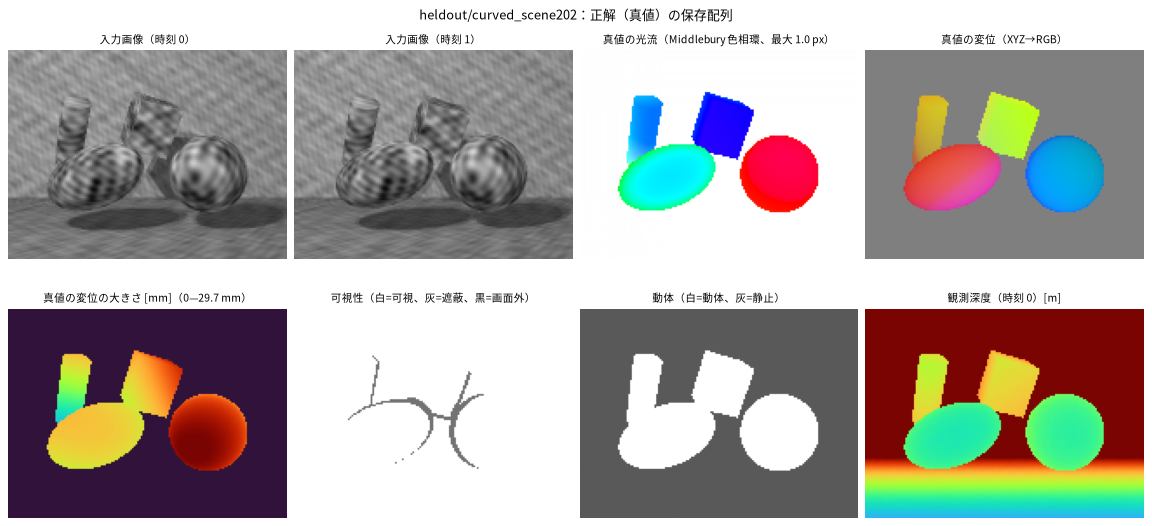

In [5]:
for case in heldout[:2]:
    print(case.key)
    figures.show(figures.figure_ground_truth(case))


## 4. 再計算する評価量の定義

理論書 §6.3 の定義を、保存配列だけから再実装したものが `rgbd_sceneflow.metrics` です。

- 評価集合 $V$: 正解可視 かつ **観測フローと観測深度の持ち上げ（`lift_observed`）が有限**
  （＝対応先が画像内で、時刻1 深度の双線形補間が欠測に当たらないこと）
- 端点誤差 $e_p = 1000\,\|S_p - S_p^\*\|$ [mm]
- 深度 RMSE は真値との差。`_observed_` は観測深度が有効な画素、`_hole_` は欠測画素、`_object_` は物体番号 2 以上
- マッチ再投影ギャップは支持点（`support > 0.5`）での $\|\text{match\_flow} - \text{flow}\|$
- 境界は物体番号の変わり目を**両側とも立ててから**膨張半径 2 の帯にする
- 物体別・物体平均は `metadata` の物体表（動体フラグ）に従う

定義は、アーカイブの数値だけから探索して復元したあと、届いた配布実装
`scene_flow_primitives/src/scene_flow_refinement/primitive_metrics.py` と突き合わせて確定しました（§7）。


## 5. 1 ケースでの突合（何が一致し、何が一致しないか）


In [6]:
case = next(c for c in iter_cases() if c.key == "heldout/gallery_scene101")
method = "standard"

recomputed = metrics.evaluate(case.inputs(), case.result(method), case.metadata())["metrics"]
documented = case.documented(method)["metrics"]
statuses = metrics.compare(recomputed, documented, approx_keys=metrics.APPROX_KEYS)

order = {"exact": 0, "approx": 1, "mismatch": 2, "not_recomputable": 3, "undefined": 4}
statuses.sort(key=lambda s: (order.get(s.status, 9), s.name))

lines = ["| メトリクス | 再計算 | 凍結値 | 状態 |", "|---|---:|---:|---|"]
for s in statuses:
    fmt = lambda v: "—" if v is None else (f"{v:.6g}" if v is not None else "—")  # noqa: E731
    lines.append(f"| `{s.name}` | {fmt(s.recomputed)} | {fmt(s.documented)} | {s.status} |")
display(Markdown("\n".join(lines[:60])))
print("表示は先頭 60 行。総数:", len(statuses))


| メトリクス | 再計算 | 凍結値 | 状態 |
|---|---:|---:|---|
| `all_visible_coverage` | 1 | 1 | exact |
| `all_visible_epe_mm` | 0.941785 | 0.941785 | exact |
| `all_visible_n` | 18744 | 18744 | exact |
| `bad10_percent` | 0.0969932 | 0.0969932 | exact |
| `bad5_percent` | 3.7504 | 3.7504 | exact |
| `bound_violation_percent` | 0 | 0 | exact |
| `boundary_coverage` | 1 | 1 | exact |
| `boundary_epe_mm` | 2.18199 | 2.18199 | exact |
| `boundary_n` | 2798 | 2798 | exact |
| `coherent_outlier_coverage` | 0 | 0 | exact |
| `coherent_outlier_epe_mm` | — | — | exact |
| `coherent_outlier_n` | 0 | 0 | exact |
| `common_visible_coverage` | 1 | 1 | exact |
| `common_visible_epe_mm` | 0.945418 | 0.945418 | exact |
| `common_visible_n` | 18558 | 18558 | exact |
| `depth0_hole_rmse_mm` | — | — | exact |
| `depth0_object_rmse_mm` | 1.98019 | 1.98019 | exact |
| `depth0_observed_rmse_mm` | 2.05503 | 2.05503 | exact |
| `depth0_rmse_mm` | 2.05503 | 2.05503 | exact |
| `depth1_hole_rmse_mm` | — | — | exact |
| `depth1_object_rmse_mm` | 1.77975 | 1.77975 | exact |
| `depth1_observed_rmse_mm` | 1.96913 | 1.96913 | exact |
| `depth1_rmse_mm` | 1.96913 | 1.96913 | exact |
| `geometry_mean_mm` | 0.495358 | 0.495358 | exact |
| `geometry_p95_mm` | 1.33931 | 1.33931 | exact |
| `interior_coverage` | 1 | 1 | exact |
| `interior_epe_mm` | 0.725879 | 0.725879 | exact |
| `interior_n` | 15760 | 15760 | exact |
| `match_reprojection_gap_mean_px` | 0.051635 | 0.051635 | exact |
| `match_reprojection_gap_p95_px` | 0.155218 | 0.155218 | exact |
| `max_estimated_motion_mm` | 50 | 50 | exact |
| `moving_coverage` | 1 | 1 | exact |
| `moving_epe_mm` | 0.84473 | 0.84473 | exact |
| `moving_flow_epe_px` | 0.103083 | 0.103083 | exact |
| `moving_n` | 6144 | 6144 | exact |
| `moving_p95_mm` | 2.7345 | 2.7345 | exact |
| `object_balanced_epe_mm` | 0.996775 | 0.996775 | exact |
| `occluded_coverage` | 1 | 1 | exact |
| `occluded_epe_mm` | 2.149 | 2.149 | exact |
| `occluded_n` | 456 | 456 | exact |
| `occluded_support_percent` | 22.807 | 22.807 | exact |
| `optical_flow_epe_px` | 0.100654 | 0.100654 | exact |
| `outlier_coverage` | 0 | 0 | exact |
| `outlier_epe_mm` | — | — | exact |
| `outlier_n` | 0 | 0 | exact |
| `outside_coverage` | 0 | 0 | exact |
| `outside_epe_mm` | — | — | exact |
| `outside_n` | 0 | 0 | exact |
| `p50_mm` | 0.436361 | 0.436361 | exact |
| `p95_mm` | 3.94362 | 3.94362 | exact |
| `p99_mm` | 7.55738 | 7.55738 | exact |
| `static_coverage` | 1 | 1 | exact |
| `static_epe_mm` | 0.99525 | 0.99525 | exact |
| `static_gray_change_coverage` | 1 | 1 | exact |
| `static_gray_change_epe_mm` | 4.08337 | 4.08337 | exact |
| `static_gray_change_n` | 312 | 312 | exact |
| `static_n` | 12414 | 12414 | exact |
| `support_percent` | 91.1667 | 91.1667 | exact |

表示は先頭 60 行。総数: 77


## 6. 70 組すべての突合


In [7]:
from collections import Counter

status_counts = Counter()
mismatches = []
per_metric = {}

for case in iter_cases():
    for method in case.methods():
        recomputed = metrics.evaluate(case.inputs(), case.result(method), case.metadata())["metrics"]
        documented = case.documented(method)["metrics"]
        for status in metrics.compare(recomputed, documented, approx_keys=metrics.APPROX_KEYS):
            status_counts[status.status] += 1
            per_metric.setdefault(status.name, Counter())[status.status] += 1
            if status.status == "mismatch":
                mismatches.append((case.key, method, status.name, status.recomputed, status.documented))

lines = ["| 状態 | 件数 | 意味 |", "|---|---:|---|"]
meanings = {
    "exact": "丸め誤差の範囲で一致",
    "approx": "定義未特定の近似（境界系）",
    "not_recomputable": "推定器内部の量（ソース不在）",
    "mismatch": "一致しない",
}
for key in ("exact", "approx", "not_recomputable", "mismatch"):
    lines.append(f"| {key} | {status_counts.get(key, 0)} | {meanings[key]} |")
display(Markdown("\n".join(lines)))
print("mismatch:", len(mismatches), mismatches[:3])
assert not mismatches, "説明できない不一致があります"


| 状態 | 件数 | 意味 |
|---|---:|---|
| exact | 4270 | 丸め誤差の範囲で一致 |
| approx | 0 | 定義未特定の近似（境界系） |
| not_recomputable | 1055 | 推定器内部の量（ソース不在） |
| mismatch | 0 | 一致しない |

mismatch: 0 []


## 7. 配布実装との突き合わせ

届いた実装 `scene_flow_primitives/` の評価関数（`lift_observed` / `region_masks` /
`score_primitive`）と、ラボ側の再実装を全 70 組で突き合わせます。
評価関数の読み込みにネイティブライブラリのビルドは要りません（遅延ロード）。


In [8]:
import sys as _sys

_sys.path.insert(0, str(LAB / "scene_flow_primitives" / "src"))
from scene_flow_refinement.metrics import lift_observed  # noqa: E402
from scene_flow_refinement.primitive_metrics import region_masks, score_primitive  # noqa: E402

worst, where, checked = 0.0, None, 0
same_common_visible = True
for case in iter_cases():
    data = case.inputs()
    metadata = case.metadata()
    raw = lift_observed(data["depth0"], data["depth1"], data["flow_observed"], data["intrinsics"])
    regions = region_masks(data, raw)
    same_common_visible &= bool((regions["common_visible"] == metrics.common_visible_set(data)).all())
    for method in case.methods():
        theirs, _ = score_primitive(data, case.result(method), regions, metadata["objects"])
        ours = metrics.evaluate(data, case.result(method), metadata)["metrics"]
        for key, value in theirs.items():
            if value is None or not isinstance(value, (int, float)):
                continue
            difference = abs(float(value) - float(ours[key]))
            if difference > worst:
                worst, where = difference, (case.key, method, key)
        checked += 1

print(f"配布実装との突合: {checked} 組／最大差 {worst:.3e} @ {where}")
print("評価集合 V が一致:", same_common_visible)
assert worst == 0.0 and same_common_visible


配布実装との突合: 70 組／最大差 0.000e+00 @ None
評価集合 V が一致: True


## 8. 誤差マップの再構成（新規条件 6 入力）

上段が前版（v0.2）、下段が標準版（第0.3版）。色は 20 mm で飽和させています。
配列から直接描き直したもので、改善の向きが理論書の図と一致することを目視できます。


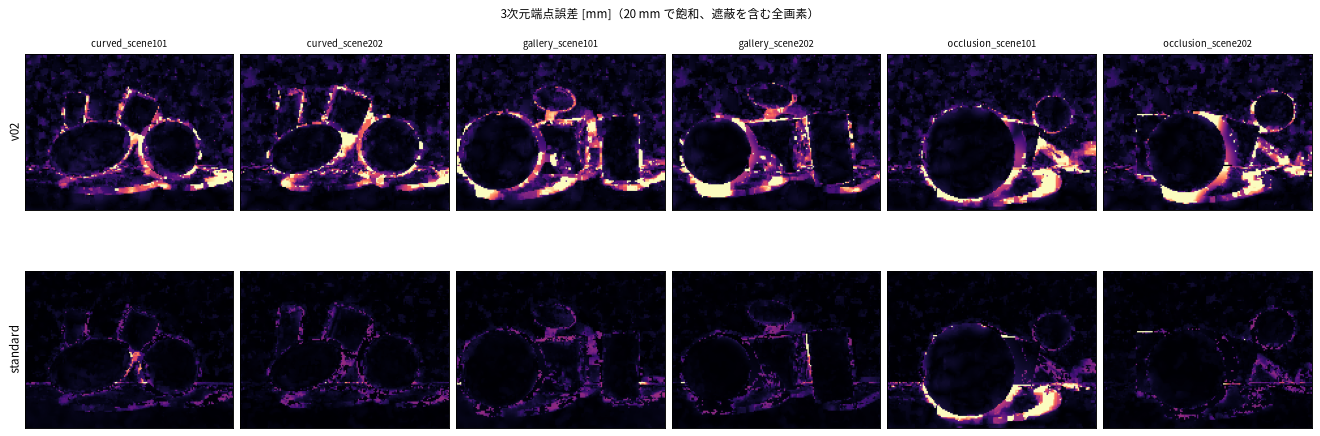

In [9]:
figures.show(figures.figure_error_maps(heldout))


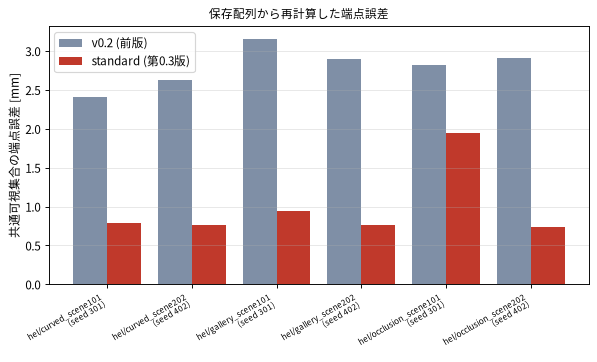

In [10]:
figures.show(figures.figure_paired_errors(heldout))


## 9. 光流の可視化スタイル

光流の定番表示を 3 つ並べます。**観測光流と推定光流を同じ色相環・同じ最大値で並べる**ので、
色の変わり方がそのまま推定の変化になります（向き＝色相、大きさ＝明度、白がゼロ）。
左下は動体の矢印（水色＝観測、赤＝推定）、右下は色相環の読み方です。


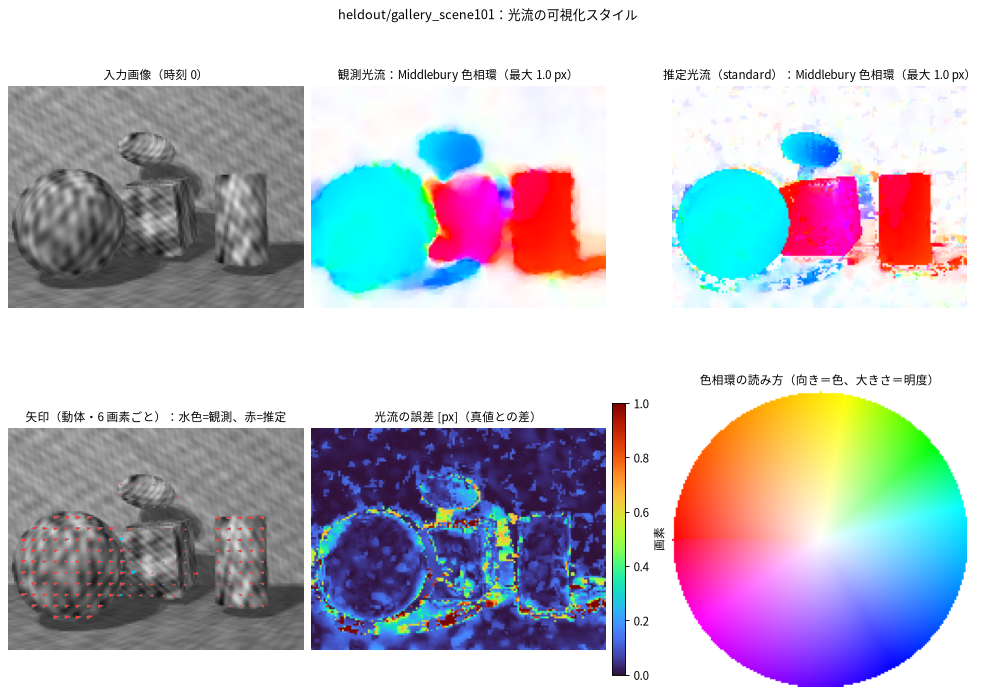

In [11]:
view_case = next(c for c in iter_cases() if c.key == "heldout/gallery_scene101")
figures.show(figures.figure_optical_flow_styles(view_case))


## 10. 3 次元変位の可視化スタイル（XYZ→RGB と大きさ）

3 次元変位は、成分をそのまま色に載せる表示（赤=x、緑=y、青=z）が定番です。
中間色が変位ゼロで、明るい側が正、暗い側が負を表します。下段は変位の大きさ [mm] です。
各軸の飽和値は正解の 99 パーセンタイルで固定しているので、**3 パネルで同じ色が同じ量**を意味します。


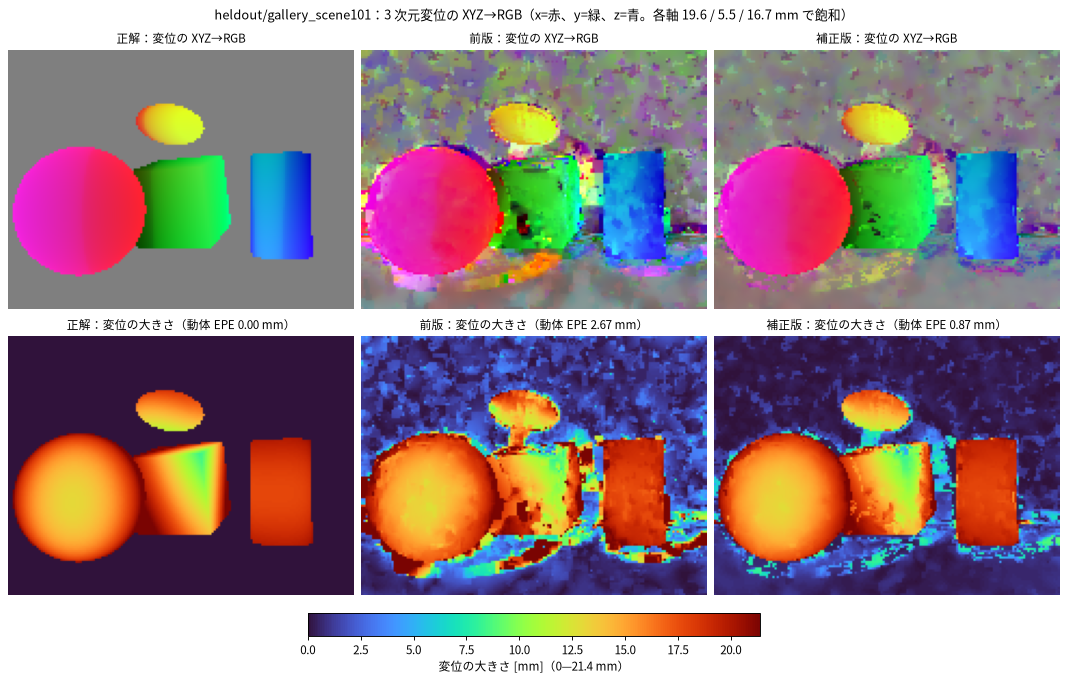

In [12]:
figures.show(figures.figure_scene_flow_styles(view_case))


## 11. 3D ビュー：点群とシーンフロー

動体の点群（観測深度で色付け）と変位ベクトル（矢印 ×5、8 画素ごと）を 3D で描きます。
**視点・表示範囲・間引き・矢印倍率を 3 パネルで揃えている**ので、矢印の向きの違いを
そのまま比較できます。背景（壁・床）は点群から外し、動体の形と動きだけを見ます。


| 表示 | 動体 EPE [mm]（再計算） |
|---|---:|
| 正解 | 0.000 |
| 前版 | 2.675 |
| 補正版 | 0.870 |

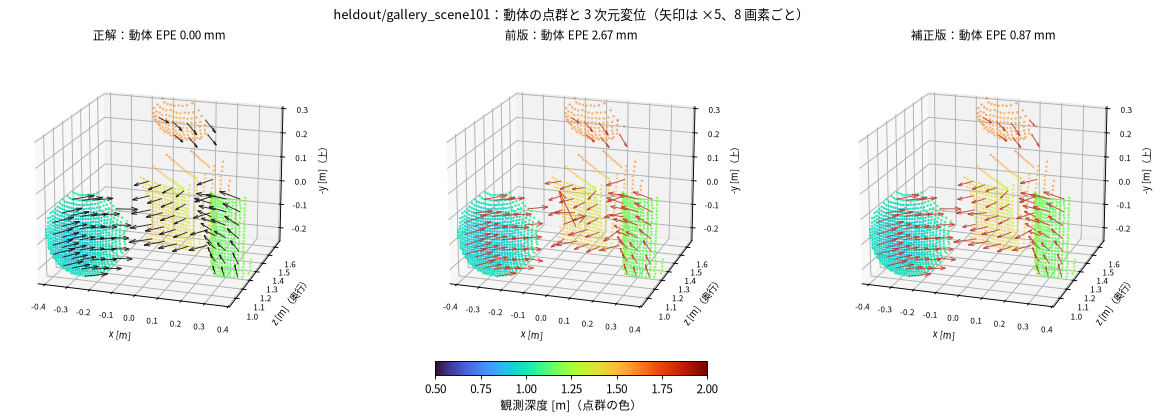

In [13]:
from rgbd_sceneflow.figures import DEFAULT_3D_VARIANTS

view_inputs = view_case.inputs()
view_moving = view_inputs["gt_labels0"] >= 2

rows = ["| 表示 | 動体 EPE [mm]（再計算） |", "|---|---:|"]
for label, method in DEFAULT_3D_VARIANTS:
    scene = view_inputs["gt_scene_flow"] if method is None else view_case.result(method)["scene_flow"]
    error = np.linalg.norm(scene - view_inputs["gt_scene_flow"], axis=-1)[view_moving].mean() * 1000.0
    rows.append(f"| {label} | {error:.3f} |")
display(Markdown("\n".join(rows)))

figures.show(figures.figure_scene_flow_3d(view_case))


同じ推定を 4 つの視点から眺めます（正面・俯瞰・斜め裏）。ビューアのように角度を変えて、
点群の形と矢印の向きが破綻していないかを確かめられます。推定は補正版（standard）です。


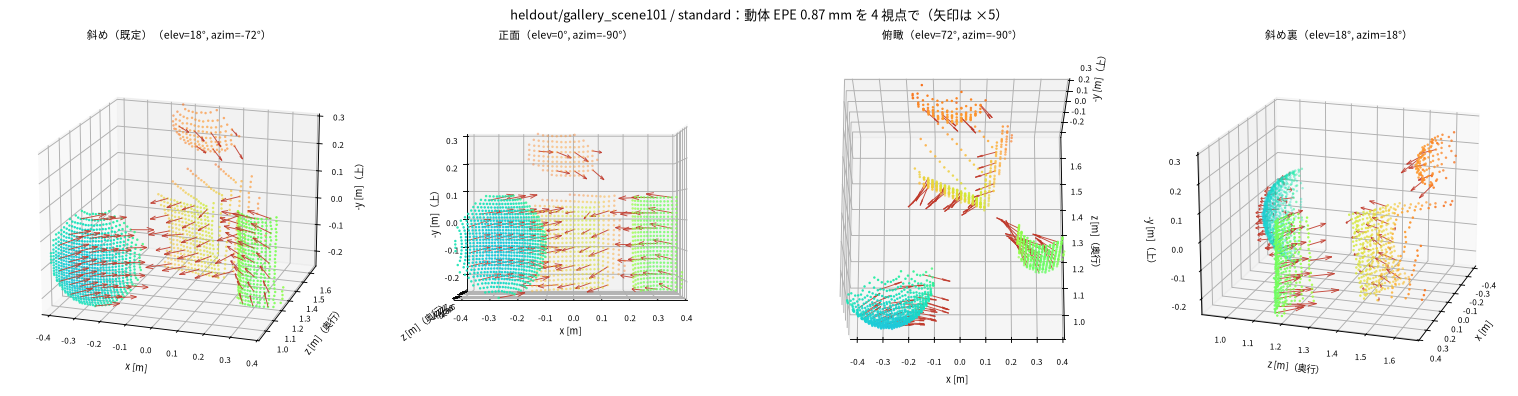

In [14]:
figures.show(figures.figure_scene_flow_3d_views(view_case))


## 12. 集計表の再構成と凍結集計との突合


In [15]:
grouped = tables.collect()
stats = tables.aggregate(grouped)
summary = archive.read_json(archive.DATA_ROOT / "summary.json")
rows = tables.compare_with_summary(stats, summary)

lines = ["| 区分 | 手法 | n | 共通可視 [mm] | 動体 [mm] | C++時間 [s] |", "|---|---|---:|---:|---:|---:|"]
for split, label in (("retest", "再試験"), ("heldout", "新規条件")):
    for method, method_label in (("v02", "第0.2版"), ("standard", "標準版")):
        stat = stats.get((split, method))
        if stat is None:
            continue
        cells = [f"{stat[k]['mean']:.3f} ± {stat[k]['sd']:.3f}" for _, k in tables.COLUMNS[:3]]
        lines.append(f"| {label} | {method_label} | {stat['n']} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(lines)))

worst = max((r["difference"] for r in rows), default=0.0)
print(f"突合した集計項目: {len(rows)}／凍結集計 summary.json との最大差: {worst:.3e}")
assert worst <= 1e-9, "凍結集計と一致しません"


| 区分 | 手法 | n | 共通可視 [mm] | 動体 [mm] | C++時間 [s] |
|---|---|---:|---:|---:|---:|
| 再試験 | 第0.2版 | 6 | 2.958 ± 0.401 | 2.025 ± 0.394 | 34.325 ± 0.760 |
| 再試験 | 標準版 | 6 | 0.852 ± 0.066 | 0.881 ± 0.104 | 9.764 ± 0.162 |
| 新規条件 | 第0.2版 | 6 | 2.804 ± 0.260 | 1.799 ± 0.452 | 34.946 ± 0.465 |
| 新規条件 | 標準版 | 6 | 0.991 ± 0.476 | 0.823 ± 0.113 | 9.890 ± 0.101 |

突合した集計項目: 48／凍結集計 summary.json との最大差: 0.000e+00


## 13. アブレーション入力の速度と精度（時間は保存値、誤差は再計算）


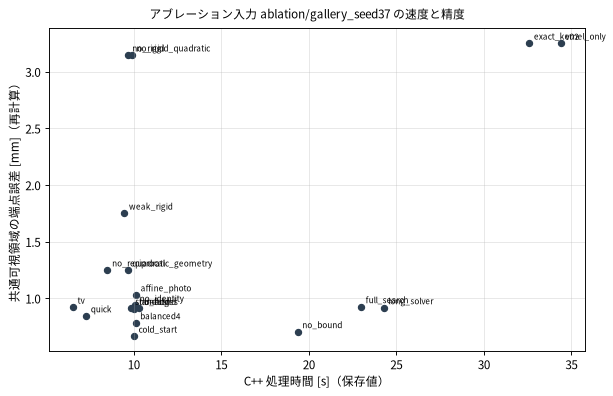

In [16]:
figures.show(figures.figure_speed_accuracy(figures.ablation_case()))


## 14. 結論

### 実行再現（届いた実装をビルドして走らせる）

配布実装 `scene_flow_primitives/` をビルドすると、記録どおりの結果が得られます（`just build` / `just upstream-test` / `just verify-upstream`）。

- 自動試験 **93 passed**（配布時の記録は 94 件。旧版 v0.1 の ABI 互換試験は、
  旧版コードを削除したため現在は含まない）
- 保存済み推定 1 件の再計算（`retest/gallery_dis_seed11`, standard）で
  **14 フィールドすべて max_abs = 0.0**（記録と同じ）

### 評価量の再現（本 Notebook と `just reproduce`）

70 組すべてで凍結メトリクスと突合し、**exact 4,270 件・不一致 0 件・近似 0 件**でした。
配布実装の評価関数との突き合わせも最大差 0.0（§7）。

### 再計算できないもの

`elapsed_seconds` などの処理時間、`candidate_*`、`fixed_point_*`、`adjoint_error`、
`rigid_components`、`inner_iterations`（1,055 件）は推定器内部の量で、保存配列からは決まりません。
時間は保存値を使い、再実行時には環境依存の差が出ます（今回 11.7 秒、記録 10.70〜10.75 秒）。

以上から、このアーカイブは **「結果の解釈」だけでなく「実装の再実行」まで再現できる**と確認できました。
一方で、実データ・欠測補完・実時間処理への一般化は理論書も主張しておらず、本 Notebook も触れていません。
